# Ensemble Models: Random Forests & Boosting
In Data Science, the term ensemble refers to an algorithm that makes use of more than one model to make a prediction.

Traditional models such as individual decision trees often suffer from overfitting or limited predicitive power.

Ensemble learning techniques provide powerful solutions by combining multiple models to improve performance.

The idea of ensembles is to bring together multiple models to use them to improve the quality of your predictions when compared to just using a single model.

## Random Forest
Random Forest is a supervised machine learning algorithm that belongs to the ensemble learning family. It builds multiple decision trees and their predictions are averaged (for regression) or decided by majority vote (for classification). 

However, since decision trees use a greedy approach to select the best feature at each step, trees trained on the same dataset tend to produce similar results. Adding more identical trees does not improve performance. Therefore, Random Forest introduces randomness through two key techniques to create diverse trees and improve prediction accuracy: **Bagging** and the **Subspace Sampling Method**.
  - Bagging - A technique used in Random Forest where multiple decision trees are trained on random subsets of the training data, with replacement, to reduce variance and prevent overfitting.
  - Subspace Sampling - Unlike a single decision tree, which considers all features when splitting nodes, Random Forest selects a random subset of features at each split. This further diversifies the model and reduces correlation between trees.

### Benefits
1. Strong Performance
2. Interpretability

### Drawbacks
1. Computational complexity
2. Memory Usage

## Boosting
Boosting is an ensemble learning technique that combines multiple weak models trained sequentially, with each new model focusing on correcting the errors of the previous ones. This improves overall prediction accuracy. Common boosting algorithms include AdaBoost, Gradient Boosting, and XGBoost. Unlike Random Forest, which trains trees independently, boosting builds models one after another to create a stronger predictive model.

How Boosting Works
1. Weak Learners

A weak learner is a simple model, often a shallow decision tree, that performs only slightly better than random guessing. Boosting combines several weak learners to create a stronger model.

2. Sequential Learning

Boosting starts by training one weak learner on the data. It then identifies the errors made by that model and trains the next learner to focus on those mistakes. This process continues until a stopping condition is reached.

3. How Boosting Corrects Errors

Each new learner focuses on the weaknesses of earlier learners. The exact method depends on the algorithm:
    - AdaBoost: Increases the weights of incorrectly classified examples so that the next learner pays more attention to them.
    - Gradient Boosting: Calculates prediction errors (residuals) and trains subsequent trees to reduce those errors by minimizing a loss function.

4. Combining Predictions

The predictions from all the weak learners are combined to produce a final prediction. In this way, several simple models work together to form a stronger model.

5. Learning Rate

The learning rate controls how much each new tree contributes to the overall model. A smaller learning rate makes improvements more gradual and usually requires more trees, while a larger rate learns faster but may not achieve the best performance.

6. XGBoost

XGBoost (Extreme Gradient Boosting) is an optimized implementation of gradient boosting designed for efficient and effective model training. It includes features such as parallel tree construction and automatic handling of missing values.

### Common Hyperparameters for Boosting Models
Boosting hyperparameters control model complexity, accuracy, overfitting, and training speed. Tuning them helps improve model performance.

| Hyperparameter         | Definition and Effect                                                                                                                                                                                 | When to Tune                                                                         | Typical Values                                                                                        |
| ---------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------ | ----------------------------------------------------------------------------------------------------- |
| 1. `n_estimators`      | Number of weak learners (trees). More trees may improve accuracy but increase training time and overfitting; fewer may cause underfitting.                                                            | Underfitting: increase. Overfitting: decrease or apply regularization.               | AdaBoost: 50–500; Gradient Boosting: 100–1,000; XGBoost: 100–2,000.                                   |
| 2. `learning_rate`     | Controls each new tree's contribution to correcting previous errors. Lower values (0.01–0.1) learn gradually and need more trees; higher values (0.3–1.0) train faster but may overfit.               | Overfitting: decrease the rate and increase trees. Slow training: increase the rate. | AdaBoost: 0.5–1.0; Gradient Boosting: 0.05–0.2; XGBoost: 0.01–0.3.                                    |
| 3. `max_depth`         | Maximum depth of each tree. Deeper trees capture complex patterns but may overfit; shallower trees generalize better but may underfit.                                                                | Overfitting: decrease (10 → 4). Underfitting: increase (3 → 7).                      | AdaBoost: 1–3 (shallow trees/stumps); Gradient Boosting: 3–10; XGBoost: 3–10.                         |
| 4. `min_samples_split` | Minimum samples required to split a node. Higher values (10–20) reduce complexity and overfitting; lower values (2–5) allow more splits.                                                              | Overfitting: increase (2 → 10). Underfitting: decrease (20 → 5).                     | AdaBoost: not commonly tuned directly because trees are shallow; Gradient Boosting and XGBoost: 2–10. |
| 5. `min_samples_leaf`  | Minimum samples required in a leaf. Higher values (10–50) simplify trees; lower values (1–5) allow smaller leaves and greater complexity.                                                             | Overfitting: increase. Underfitting: decrease.                                       | AdaBoost: not commonly tuned; Gradient Boosting and XGBoost: 1–20.                                    |
| 6. `subsample`         | Fraction of training data used for each tree. Lower values (0.5–0.8) add randomness and may reduce overfitting; higher values (0.9–1.0) use more data but may increase variance.                      | Overfitting: decrease (1.0 → 0.7). Underfitting: increase (0.6 → 0.9).               | AdaBoost: not applicable; Gradient Boosting and XGBoost: 0.5–1.0.                                     |
| 7. `colsample_bytree`  | Fraction of features randomly selected for each tree. Lower values (0.5–0.8) increase tree diversity and may reduce overfitting; higher values (0.9–1.0) use more features but may increase variance. | Overfitting: decrease (1.0 → 0.8). Underfitting: increase (0.5 → 0.9).               | AdaBoost: not applicable; Gradient Boosting and XGBoost: 0.5–1.0.                                     |

Key takeaway: Increase model complexity when underfitting and reduce it when overfitting. The best hyperparameter values depend on the dataset and should be evaluated using validation data.

In [24]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


In [25]:
# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for splitting data and evaluating models
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

In [26]:
# Load the dataset
df = pd.read_csv("bank.csv", sep=None, engine="python")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# View the first five rows
print(df.head())

# Check the dataset structure
df.info()

# Check for missing values
print(df.isnull().sum())

# Check the target variable
print(df["deposit"].value_counts())

   age         job  marital  education default  balance housing loan  contact  \
0   59      admin.  married  secondary      no     2343     yes   no  unknown   
1   56      admin.  married  secondary      no       45      no   no  unknown   
2   41  technician  married  secondary      no     1270     yes   no  unknown   
3   55    services  married  secondary      no     2476     yes   no  unknown   
4   54      admin.  married   tertiary      no      184      no   no  unknown   

   day month  duration  campaign  pdays  previous poutcome deposit  
0    5   may      1042         1     -1         0  unknown     yes  
1    5   may      1467         1     -1         0  unknown     yes  
2    5   may      1389         1     -1         0  unknown     yes  
3    5   may       579         1     -1         0  unknown     yes  
4    5   may       673         2     -1         0  unknown     yes  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 

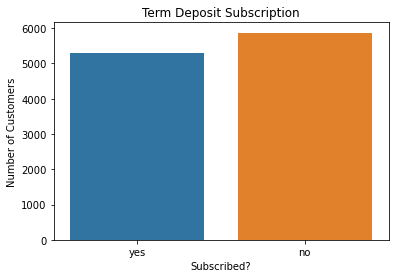

Features shape: (11162, 15)
Target shape: (11162,)

Target distribution:
0    5873
1    5289
Name: deposit, dtype: int64


In [27]:
# Visualize the number of customers who subscribed
sns.countplot(data=df, x="deposit")

plt.title("Term Deposit Subscription")
plt.xlabel("Subscribed?")
plt.ylabel("Number of Customers")
plt.show()

# Convert the target variable into numerical values
# yes = 1, no = 0

df["deposit"] = (
    df["deposit"].astype(str).str.strip().str.lower()
    .map({"yes": 1, "no": 0})
)

# Remove rows with missing or invalid target values
df = df.dropna(subset=["deposit"])

# Convert target to integer
df["deposit"] = df["deposit"].astype(int)

# Separate features and target
X = df.drop(columns=["deposit"])
y = df["deposit"]

# Remove duration to avoid using information only available
# after a marketing call has taken place
if "duration" in X.columns:
    X = X.drop(columns=["duration"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

In [40]:
# Split the data into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
    
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (8929, 15)
Testing features: (2233, 15)

Training target distribution:
0    0.526151
1    0.473849
Name: deposit, dtype: float64

Testing target distribution:
0    0.526198
1    0.473802
Name: deposit, dtype: float64


In [29]:
# Find columns containing numbers
numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Find columns containing categories or text
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [30]:
# Create an imputer for numerical columns
numerical_imputer = SimpleImputer(strategy="median")

# Learn the median from training data and apply it
X_train[numerical_cols] = numerical_imputer.fit_transform(
    X_train[numerical_cols]
)

X_test[numerical_cols] = numerical_imputer.transform(
    X_test[numerical_cols]
)

# Create an imputer for categorical columns
categorical_imputer = SimpleImputer(strategy="most_frequent")

# Learn the most frequent category from training data
X_train[categorical_cols] = categorical_imputer.fit_transform(
    X_train[categorical_cols]
)

X_test[categorical_cols] = categorical_imputer.transform(
    X_test[categorical_cols]
)

print("Missing values in training data:", X_train.isnull().sum())
print("Missing values in testing data:", X_test.isnull().sum())

Missing values in training data: age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
campaign     0
pdays        0
previous     0
poutcome     0
dtype: int64
Missing values in testing data: age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
campaign     0
pdays        0
previous     0
poutcome     0
dtype: int64


In [31]:
# Convert categorical columns into numerical indicator columns
X_train = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Make sure training and testing data have the same columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Training data after encoding:", X_train.shape)
print("Testing data after encoding:", X_test.shape)

print("\nEncoded feature names:")
print(X_train.columns.tolist())

Training data after encoding: (8929, 41)
Testing data after encoding: (2233, 41)

Encoded feature names:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown', 'marital_married', 'marital_single', 'education_secondary', 'education_tertiary', 'education_unknown', 'default_yes', 'housing_yes', 'loan_yes', 'contact_telephone', 'contact_unknown', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'poutcome_other', 'poutcome_success', 'poutcome_unknown']


Random Forest Accuracy:
0.729064039408867

Random Forest Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.71      0.81      0.76      1166
   Subscription       0.76      0.64      0.69      1067

       accuracy                           0.73      2233
      macro avg       0.73      0.73      0.73      2233
   weighted avg       0.73      0.73      0.73      2233



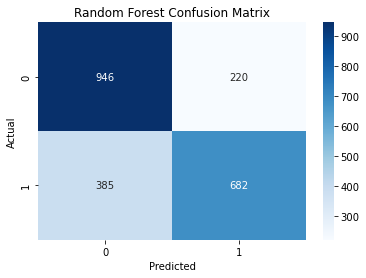

In [32]:
# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Accuracy:")
print(accuracy_score(y_test, y_pred_rf))

print("\nRandom Forest Classification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

AdaBoost Accuracy:
0.716077026421854

AdaBoost Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.68      0.87      0.76      1166
   Subscription       0.79      0.55      0.65      1067

       accuracy                           0.72      2233
      macro avg       0.73      0.71      0.71      2233
   weighted avg       0.73      0.72      0.71      2233



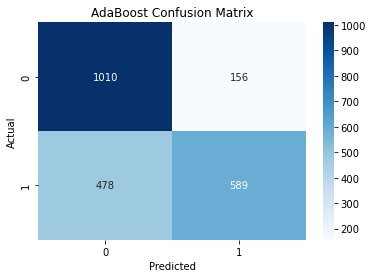

In [33]:
# Create the AdaBoost model
ada_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train the model
ada_model.fit(X_train, y_train)

# Make predictions
y_pred_ada = ada_model.predict(X_test)

# Evaluate the model
print("AdaBoost Accuracy:")
print(accuracy_score(y_test, y_pred_ada))

print("\nAdaBoost Classification Report:")
print(classification_report(
    y_test,
    y_pred_ada,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_ada)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("AdaBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Gradient Boosting Accuracy:
0.7447380206000895

Gradient Boosting Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.71      0.87      0.78      1166
   Subscription       0.81      0.61      0.69      1067

       accuracy                           0.74      2233
      macro avg       0.76      0.74      0.74      2233
   weighted avg       0.76      0.74      0.74      2233



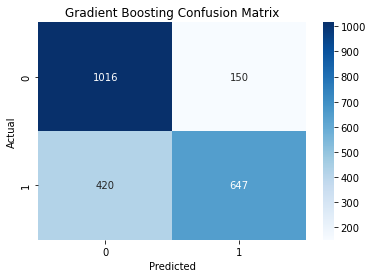

In [34]:
# Create the Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

# Make predictions
y_pred_gb = gb_model.predict(X_test)

# Evaluate the model
print("Gradient Boosting Accuracy:")
print(accuracy_score(y_test, y_pred_gb))

print("\nGradient Boosting Classification Report:")
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_gb)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Gradient Boosting Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

XGBoost Accuracy:
0.7411553963278101

XGBoost Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.70      0.87      0.78      1166
   Subscription       0.81      0.60      0.69      1067

       accuracy                           0.74      2233
      macro avg       0.76      0.74      0.73      2233
   weighted avg       0.75      0.74      0.74      2233



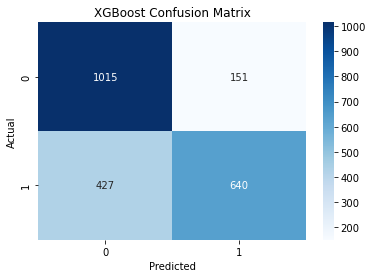

In [35]:
# Create the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate the model
print("XGBoost Accuracy:")
print(accuracy_score(y_test, y_pred_xgb))

print("\nXGBoost Classification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_xgb)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [36]:
# Store predictions from each model
model_predictions = {
    "Random Forest": y_pred_rf,
    "AdaBoost": y_pred_ada,
    "Gradient Boosting": y_pred_gb,
    "XGBoost": y_pred_xgb
}

# Collect the evaluation metrics
results = []

for model_name, predictions in model_predictions.items():

    accuracy = accuracy_score(y_test, predictions)

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "F1-score": f1
    })

# Display the comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
)

print(results_df.to_string(index=False))

            Model  Accuracy  F1-score
Gradient Boosting  0.744738  0.694206
    Random Forest  0.729064  0.692737
          XGBoost  0.741155  0.688913
         AdaBoost  0.716077  0.650110


In [37]:
# Define the hyperparameter combinations to test
param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5, 7]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1
    ),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

# Train and compare the parameter combinations
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(grid_search.best_score_)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best Parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}

Best Cross-Validation F1-score:
0.6934509217676454


Final Tuned XGBoost Accuracy:
0.7407075682937752

Final Tuned XGBoost Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.71      0.85      0.77      1166
   Subscription       0.79      0.62      0.70      1067

       accuracy                           0.74      2233
      macro avg       0.75      0.74      0.73      2233
   weighted avg       0.75      0.74      0.74      2233



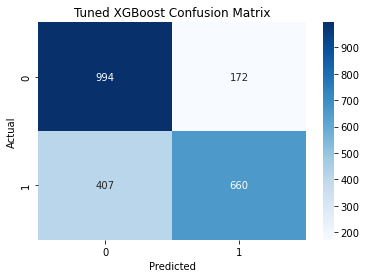

In [38]:
# Extract the best model found during tuning
best_xgb = grid_search.best_estimator_

# Make predictions on the unseen test set
y_pred_final = best_xgb.predict(X_test)

# Calculate final metrics
print("Final Tuned XGBoost Accuracy:")
print(accuracy_score(y_test, y_pred_final))

print("\nFinal Tuned XGBoost Classification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))

# Plot the final confusion matrix
cm = confusion_matrix(y_test, y_pred_final)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Tuned XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Top 10 Important Features:
         Feature  Importance
poutcome_success    0.345960
 contact_unknown    0.079628
       month_mar    0.067962
     housing_yes    0.058686
       month_sep    0.045841
       month_oct    0.038152
       month_jun    0.036604
        loan_yes    0.028553
       month_feb    0.027330
 marital_married    0.022489


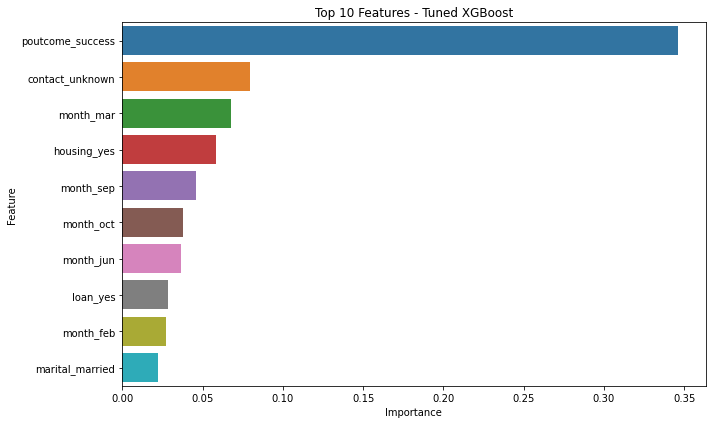

In [39]:
# Get the importance scores from the tuned XGBoost model
importance_scores = best_xgb.feature_importances_

# Match each score with its feature name
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance_scores
})

# Sort features from most to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Select the top 10
top_features = feature_importance.head(10)

print("Top 10 Important Features:")
print(top_features.to_string(index=False))

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features - Tuned XGBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()